# Homework 1: Source modeling
Falasco Jacopo - 2194529

Google Meet outgoing traffic. Run the cells from top to bottom and upload
`meet_outgoing.csv` when requested.

## 1. Load the data
Load the original CSV and define the functions used for tables, figures and CDF comparisons.

In [1]:
# Load data
from pathlib import Path
import hashlib
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

pd.options.display.float_format = '{:.6f}'.format
output_dir = Path('results_final')
output_dir.mkdir(exist_ok=True)
saved_files = []

csv_path = Path('meet_outgoing.csv')
if not csv_path.is_file():
    from google.colab import files
    uploaded = files.upload()
    if list(uploaded) != ['meet_outgoing.csv']:
        raise ValueError('Upload only meet_outgoing.csv.')

raw = pd.read_csv(csv_path)
input_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
print(f'Loaded file: {csv_path.name}')
print(f'Rows: {len(raw)}')
display(raw.head(3))


Loaded file: meet_outgoing.csv
Rows: 39083


,No.,Time,Source,Destination,Protocol,Length,Total Length,Info
0,16959,60.004494,192.168.1.7,74.125.250.248,UDP,241,227,61626 > 3478 Len=199
1,16960,60.005909,192.168.1.7,74.125.250.248,UDP,1155,1141,61626 > 3478 Len=1113
2,16961,60.005973,192.168.1.7,74.125.250.248,UDP,1155,1141,61626 > 3478 Len=1113


In [2]:
# Functions
def empirical_cdf(x):
    values, counts = np.unique(x, return_counts=True)
    return np.r_[values[0], values], np.r_[0, np.cumsum(counts) / len(x)]

def save_table(table, name):
    path = output_dir / f'{name}.csv'
    table.to_csv(path, index=False)
    saved_files.append(path)

def save_figure(fig, name):
    for extension in ['png', 'pdf']:
        path = output_dir / f'{name}.{extension}'
        fig.savefig(path, dpi=250, bbox_inches='tight')
        saved_files.append(path)
    plt.show()
    plt.close(fig)

def cdf_gap(x, cdf):
    values, counts = np.unique(x, return_counts=True)
    right = np.cumsum(counts) / len(x)
    left = right - counts / len(x)
    before = np.nextafter(values.astype(float), -np.inf)
    return max(np.max(np.abs(right - cdf(values))),
               np.max(np.abs(left - cdf(before))))

def sample_cdf_distance(x, y):
    values = np.union1d(x, y)
    f_x = np.searchsorted(np.sort(x), values, side='right') / len(x)
    f_y = np.searchsorted(np.sort(y), values, side='right') / len(y)
    return float(np.max(np.abs(f_x - f_y)))


## 2. Measure the traffic
Compute packet statistics, then group consecutive packet gaps of at most 0.5 ms.
Use batch intervals $A_i$, batch sizes $B_i$ and individual IP workloads $W_{i,k}$.

In [3]:
# Packet data
t_start, t_end = 60.0, 299.974147
T = t_end - t_start
required = {'No.', 'Time', 'Source', 'Destination', 'Total Length'}
if not required.issubset(raw.columns):
    raise ValueError(f'Missing columns: {sorted(required - set(raw.columns))}')

df = raw.copy()
numeric = ['No.', 'Time', 'Total Length']
df[numeric] = df[numeric].apply(pd.to_numeric, errors='raise')
assert np.isfinite(df[numeric].to_numpy()).all(), 'Non-finite measurements.'
assert len(df) == 39083 and df['No.'].is_unique, 'Unexpected original CSV.'
assert (df['Source'] == '192.168.1.7').all(), 'Unexpected source address.'
assert (df['Destination'] == '74.125.250.248').all(), 'Unexpected destination.'
assert df['Time'].between(t_start, t_end).all(), 'Timestamps outside the window.'
assert (np.diff(df['Time']) > 0).all(), 'Timestamps must increase strictly.'
assert ((df['Total Length'] > 0) & (df['Total Length'] % 1 == 0)).all()

tau_packet = df['Time'].to_numpy() - t_start
A_packet = np.diff(tau_packet)
W = 8 * df['Total Length'].to_numpy(dtype=int)
G = W.sum() / T
packets = pd.DataFrame({'tau_packet_s': tau_packet, 'W_i_k_bits': W})

packet_summary = pd.DataFrame({
    'Metric': ['Packet count', 'Packet inter-arrival count', 'Window duration [s]',
               'Mean packet inter-arrival [ms]', 'Packet inter-arrival std [ms]',
               'Packet inter-arrival CV', 'Mean packet workload [bits]',
               'Packet workload std [bits]', 'Total IP bits', 'IP rate [Mbit/s]'],
    'Value': [len(W), len(A_packet), T, 1000 * A_packet.mean(),
              1000 * A_packet.std(ddof=1), A_packet.std(ddof=1) / A_packet.mean(),
              W.mean(), W.std(ddof=1), int(W.sum()), G / 1e6],
})
display(packet_summary)


,Metric,Value
0,Packet count,39083.000000
1,Packet inter-arrival count,39082.000000
2,Window duration [s],239.974147
3,Mean packet inter-arrival [ms],6.139882
4,Packet inter-arrival std [ms],9.788222
5,Packet inter-arrival CV,1.594204
6,Mean packet workload [bits],6910.024512
7,Packet workload std [bits],3458.854189
8,Total IP bits,270064488.000000
9,IP rate [Mbit/s],1.125390


In [4]:
# Batch data
delta_ms = 0.5
is_start = np.r_[True, A_packet > delta_ms / 1000]
packets['i'] = np.cumsum(is_start)
packets['k'] = packets.groupby('i').cumcount() + 1
batches = packets.groupby('i', as_index=False).agg(
    tau_i_s=('tau_packet_s', 'first'),
    B_i=('W_i_k_bits', 'size'),
    total_batch_bits=('W_i_k_bits', 'sum'),
)
batches['A_i_s'] = batches['tau_i_s'].diff()
A = batches['A_i_s'].dropna().to_numpy()
B = batches['B_i'].to_numpy(dtype=int)
assert B.sum() == len(W), 'Grouping must preserve every packet.'
assert batches['total_batch_bits'].sum() == W.sum(), 'Grouping must preserve bits.'

def describe_sample(name, x, unit):
    return {'Variable': name, 'Unit': unit, 'Samples': len(x),
            'Mean': np.mean(x), 'Sample variance': np.var(x, ddof=1),
            'Sample std': np.std(x, ddof=1),
            'CV': np.std(x, ddof=1) / np.mean(x),
            'Minimum': np.min(x), 'Q25': np.quantile(x, 0.25),
            'Median': np.median(x), 'Q75': np.quantile(x, 0.75),
            'Q99': np.quantile(x, 0.99), 'Maximum': np.max(x)}

sample_summary = pd.DataFrame([
    describe_sample('A_i (batch inter-arrival)', 1000 * A, 'ms'),
    describe_sample('B_i (batch size)', B, 'packets'),
    describe_sample('W_i,k (individual packet workload)', W, 'bits'),
])
sizes, counts = np.unique(B, return_counts=True)
batch_pmf = pd.DataFrame({'B_i': sizes, 'Count': counts,
                          'Probability': counts / len(B)})
print(f'Grouping threshold: {delta_ms:.1f} ms')
print(f'Batches: {len(B)}; batch inter-arrival times: {len(A)}')
display(sample_summary)
display(batch_pmf)


Grouping threshold: 0.5 ms
Batches: 15883; batch inter-arrival times: 15882


,Variable,Unit,Samples,Mean,Sample variance,Sample std,CV,Minimum,Q25,Median,Q75,Q99,Maximum
0,A_i (batch inter-arrival),ms,15882,15.108858,103.194347,10.158462,0.672351,0.502600,6.562625,13.676800,20.417500,39.747962,62.640000
1,B_i (batch size),packets,15883,2.460681,2.513046,1.585259,0.644236,1.000000,1.000000,1.000000,4.000000,5.000000,14.000000
2,"W_i,k (individual packet workload)",bits,39083,6910.024512,11963672.298156,3458.854189,0.500556,576.000000,1952.000000,8688.000000,9216.000000,9832.000000,9936.000000


,B_i,Count,Probability
0,1,8144,0.512749
1,2,579,0.036454
2,3,63,0.003967
3,4,6100,0.384058
4,5,852,0.053642
5,6,108,0.006800
6,7,26,0.001637
7,8,7,0.000441
8,9,1,0.000063
9,10,1,0.000063


## 3. Plot the measured distributions
Inspect the interval histogram, batch-size PMF, workload histogram and empirical CDFs.

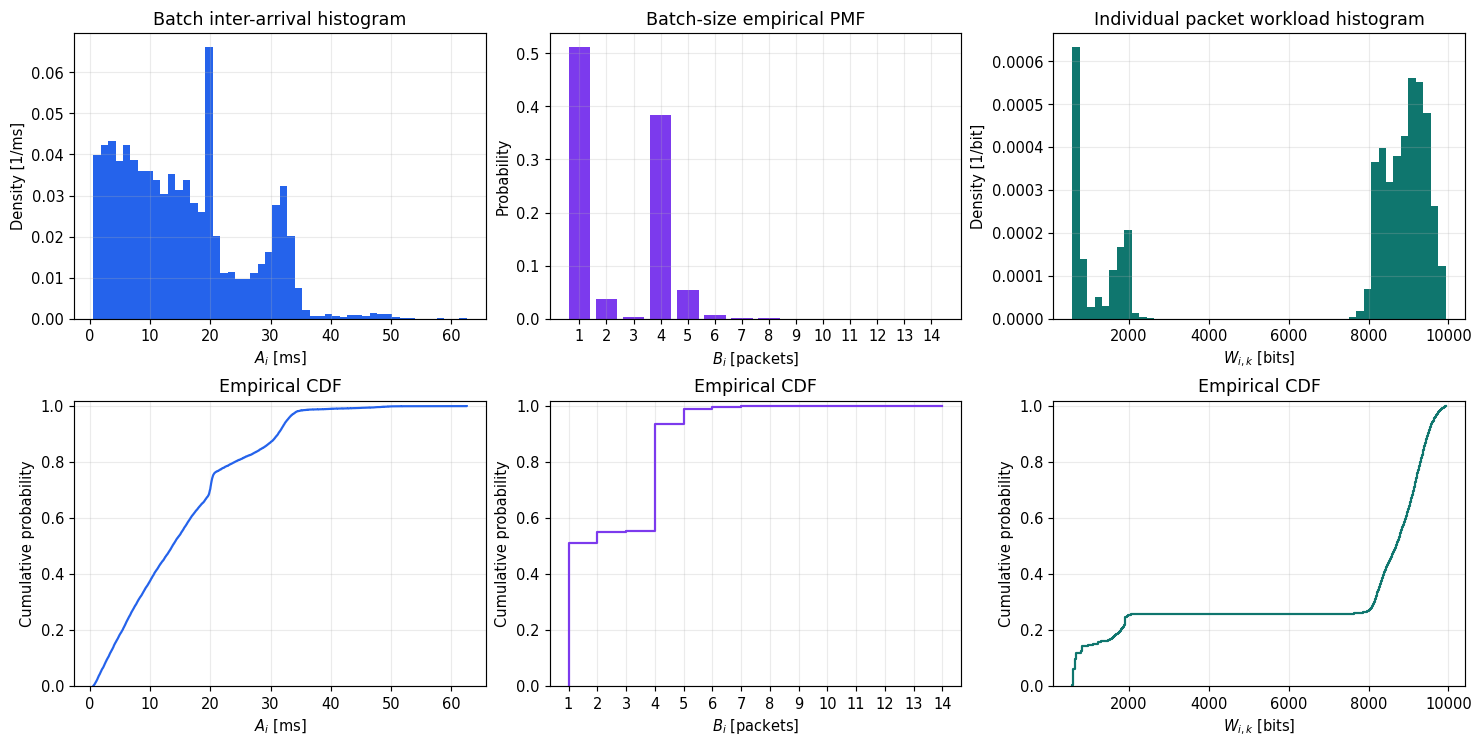

In [5]:
# Empirical plots
fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
axes[0, 0].hist(1000 * A, bins=50, density=True, color='#2563EB')
axes[0, 0].set(title='Batch inter-arrival histogram',
               xlabel=r'$A_i$ [ms]', ylabel='Density [1/ms]')
axes[0, 1].bar(sizes, counts / len(B), color='#7C3AED')
axes[0, 1].set(title='Batch-size empirical PMF',
               xlabel=r'$B_i$ [packets]', ylabel='Probability')
axes[0, 1].set_xticks(np.arange(1, B.max() + 1))
axes[0, 2].hist(W, bins=50, density=True, color='#0F766E')
axes[0, 2].set(title='Individual packet workload histogram',
               xlabel=r'$W_{i,k}$ [bits]', ylabel='Density [1/bit]')
for ax, x, label, color in zip(
    axes[1], [1000 * A, B, W],
    [r'$A_i$ [ms]', r'$B_i$ [packets]', r'$W_{i,k}$ [bits]'],
    ['#2563EB', '#7C3AED', '#0F766E']
):
    ax.step(*empirical_cdf(x), where='post', color=color)
    ax.set(xlabel=label, ylabel='Cumulative probability', ylim=(0, 1.02),
           title='Empirical CDF')
axes[1, 1].set_xticks(np.arange(1, B.max() + 1))
for ax in axes.flat:
    ax.grid(alpha=0.25)
save_figure(fig, '01_Empirical_Distributions')


## 4. Estimate the models
Use Gamma intervals, $B_i=1+Z_i(3+X_i)$ with Bernoulli and Poisson variables,
and a two-normal workload mixture conditioned on positive values.
Estimate parameters from the measured data and compare CDF distances with simple reference laws.

In [6]:
# Simple models
m_A, v_A = A.mean(), A.var(ddof=1)
m_B = B.mean()
m_W, v_W = W.mean(), W.var(ddof=1)
k_A, lambda_A = m_A**2 / v_A, m_A / v_A
k_W, lambda_W = m_W**2 / v_W, m_W / v_W
p_geom, lambda_poisson = 1 / m_B, m_B - 1

models = {
    'A_i': {
        'Exponential': stats.expon(scale=m_A),
        'Gamma': stats.gamma(a=k_A, scale=1 / lambda_A),
    },
    'B_i': {
        'Geometric': stats.geom(p=p_geom),
        'Poisson + 1': stats.poisson(mu=lambda_poisson, loc=1),
    },
    'W_i,k': {
        'Normal': stats.norm(loc=m_W, scale=np.sqrt(v_W)),
        'Gamma': stats.gamma(a=k_W, scale=1 / lambda_W),
    },
}
samples = {'A_i': A, 'B_i': B, 'W_i,k': W}


In [7]:
# Batch model
m_B, v_B = B.mean(), B.var(ddof=1)
d_B = m_B - 1
h_B = (v_B + d_B**2) / d_B - 1
c_B = (h_B + np.sqrt(h_B**2 + 12)) / 2
p_B = d_B / c_B
lambda_B = c_B - 3
assert 0 < p_B < 1 and lambda_B > 0

def batch_poisson_pmf(x):
    x = np.asarray(x)
    return ((1 - p_B) * (x == 1)
            + p_B * stats.poisson.pmf(x - 4, mu=lambda_B))

def batch_poisson_cdf(x):
    x = np.asarray(x)
    return ((1 - p_B) * (x >= 1)
            + p_B * stats.poisson.cdf(x - 4, mu=lambda_B))

def draw_batch_poisson(size, rng):
    z = rng.binomial(1, p_B, size=size)
    x = rng.poisson(lambda_B, size=size)
    return 1 + z * (3 + x)


In [8]:
# Workload model
threshold_W = 5000
W_small = W[W < threshold_W]
W_large = W[W >= threshold_W]
assert len(W_small) > 1 and len(W_large) > 1

pi_small = len(W_small) / len(W)
mu_small, sigma_small = W_small.mean(), W_small.std(ddof=1)
mu_large, sigma_large = W_large.mean(), W_large.std(ddof=1)
normal_small = stats.norm(loc=mu_small, scale=sigma_small)
normal_large = stats.norm(loc=mu_large, scale=sigma_large)

workload_parameters = pd.DataFrame({
    'Group': ['Small', 'Large'],
    'Packets': [len(W_small), len(W_large)],
    'Probability': [pi_small, 1 - pi_small],
    'Mean [bits]': [mu_small, mu_large],
    'Std [bits]': [sigma_small, sigma_large],
})
display(workload_parameters)

def workload_mixture_pdf(x):
    return pi_small * normal_small.pdf(x) + (1 - pi_small) * normal_large.pdf(x)

def workload_mixture_cdf(x):
    return pi_small * normal_small.cdf(x) + (1 - pi_small) * normal_large.cdf(x)

negative_probability = float(workload_mixture_cdf(0))

def positive_workload_cdf(x):
    x = np.asarray(x, dtype=float)
    return np.where(x > 0,
                    (workload_mixture_cdf(x) - negative_probability)
                    / (1 - negative_probability), 0.0)

def draw_positive_workloads(size, rng):
    values = np.empty(size)
    for k in range(size):
        value = -1.0
        while value <= 0:
            if rng.random() < pi_small:
                value = rng.normal(mu_small, sigma_small)
            else:
                value = rng.normal(mu_large, sigma_large)
        values[k] = value
    return values

def positive_workload_pdf(x):
    x = np.asarray(x, dtype=float)
    return np.where(
        x > 0, workload_mixture_pdf(x) / (1 - negative_probability), 0.0
    )


,Group,Packets,Probability,Mean [bits],Std [bits]
0,Small,10139,0.259422,1130.397870,558.102753
1,Large,28944,0.740578,8934.611111,494.674194


In [9]:
# Tables
parameter_table = pd.DataFrame({
    'Parameter': ['lambda_A [1/s]', 'k_A', 'p_B', 'lambda_B',
                  'pi_small', 'mu_small [bits]', 'sigma_small [bits]',
                  'mu_large [bits]', 'sigma_large [bits]'],
    'Value': [lambda_A, k_A, p_B, lambda_B, pi_small,
              mu_small, sigma_small, mu_large, sigma_large],
})

candidate_cdfs = {
    'A_i': {
        'Exponential': models['A_i']['Exponential'].cdf,
        'Gamma': models['A_i']['Gamma'].cdf,
    },
    'B_i': {
        'Geometric': models['B_i']['Geometric'].cdf,
        'Poisson + 1': models['B_i']['Poisson + 1'].cdf,
        'Bernoulli-Poisson': batch_poisson_cdf,
    },
    'W_i,k': {
        'Normal': models['W_i,k']['Normal'].cdf,
        'Gamma': models['W_i,k']['Gamma'].cdf,
        'Gaussian mixture (positive)': positive_workload_cdf,
    },
}
fit_comparison = pd.DataFrame([
    {'Variable': name, 'Model': label,
     'CDF distance D': cdf_gap(samples[name], cdf)}
    for name, candidates in candidate_cdfs.items()
    for label, cdf in candidates.items()
])
display(parameter_table)
display(fit_comparison)
print(f'Measured batches of size 2 or 3: {100 * np.mean(np.isin(B, [2, 3])):.3f}%')
print(f'Original workload mixture mass at W <= 0: {100 * negative_probability:.6f}%')


,Parameter,Value
0,lambda_A [1/s],146.411680
1,k_A,2.212113
2,p_B,0.465576
3,lambda_B,0.137361
4,pi_small,0.259422
5,mu_small [bits],1130.397870
6,sigma_small [bits],558.102753
7,mu_large [bits],8934.611111
8,sigma_large [bits],494.674194


,Variable,Model,CDF distance D
0,A_i,Exponential,0.108498
1,A_i,Gamma,0.063117
2,B_i,Geometric,0.237660
3,B_i,Poisson + 1,0.280671
4,B_i,Bernoulli-Poisson,0.021674
5,"W_i,k",Normal,0.354651
6,"W_i,k",Gamma,0.410028
7,"W_i,k",Gaussian mixture (positive),0.073252


Measured batches of size 2 or 3: 4.042%
Original workload mixture mass at W <= 0: 0.555465%


## 5. Generate the synthetic trace
Use seed 42 and the same observation duration. Compare packet counts, batch counts,
sample moments and average IP rate with the measurements.

In [10]:
# Simulation
rng = np.random.default_rng(42)
times_final, sizes_final, workloads_final = [], [], []
time = 0.0

while True:
    time += models['A_i']['Gamma'].rvs(random_state=rng)
    if time >= T:
        break
    size = int(draw_batch_poisson(1, rng)[0])
    times_final.append(time)
    sizes_final.append(size)
    workloads_final.append(draw_positive_workloads(size, rng))

tau_final = np.asarray(times_final)
A_final = np.diff(tau_final)
B_final = np.asarray(sizes_final, dtype=int)
W_final = np.concatenate(workloads_final)

packets_final = pd.DataFrame({
    'i': np.repeat(np.arange(1, len(B_final) + 1), B_final),
    'tau_packet_s': np.repeat(tau_final, B_final),
    'W_i_k_bits': W_final,
})
packets_final['k'] = packets_final.groupby('i').cumcount() + 1

batches_final = pd.DataFrame({
    'i': np.arange(1, len(B_final) + 1),
    'tau_i_s': tau_final,
    'B_i': B_final,
    'A_i_s': np.r_[np.nan, A_final],
})
batches_final['total_batch_bits'] = (
    packets_final.groupby('i')['W_i_k_bits'].sum().to_numpy()
)
assert B_final.sum() == len(W_final) and (W_final > 0).all()

def final_summary(a, b, w):
    return [len(b), len(w), 1000 * a.mean(), 1000 * a.std(ddof=1),
            b.mean(), b.std(ddof=1), w.mean(), w.std(ddof=1),
            w.sum() / T / 1e6]

final_statistics = pd.DataFrame({
    'Metric': ['Batch count', 'Packet count',
               'Mean A_i [ms]', 'Std A_i [ms]',
               'Mean B_i [packets]', 'Std B_i [packets]',
               'Mean W_i,k [bits]', 'Std W_i,k [bits]',
               'IP rate [Mbit/s]'],
    'Measured': final_summary(A, B, W),
    'Synthetic': final_summary(A_final, B_final, W_final),
})
final_statistics['Difference [%]'] = 100 * (
    final_statistics['Synthetic'] / final_statistics['Measured'] - 1
)
display(final_statistics)

final_cdfs = {
    'A_i': models['A_i']['Gamma'].cdf,
    'B_i': batch_poisson_cdf,
    'W_i,k': positive_workload_cdf,
}
final_measured = {'A_i': A, 'B_i': B, 'W_i,k': W}
final_synthetic = {'A_i': A_final, 'B_i': B_final, 'W_i,k': W_final}

final_distances = pd.DataFrame([
    {
        'Variable': name,
        'Measured vs model D': cdf_gap(final_measured[name], cdf),
        'Measured vs synthetic D': sample_cdf_distance(
            final_measured[name], final_synthetic[name]),
        'Synthetic vs model D': cdf_gap(final_synthetic[name], cdf),
    }
    for name, cdf in final_cdfs.items()
])
display(final_distances)
print(f'Analysis duration: {T:.6f} s')

save_table(final_statistics, 'final_synthetic_statistics')
save_table(final_distances, 'final_synthetic_cdf_distances')
save_table(packets_final, 'final_synthetic_packets')
save_table(batches_final, 'final_synthetic_batches')


,Metric,Measured,Synthetic,Difference [%]
0,Batch count,15883.000000,15909.000000,0.163697
1,Packet count,39083.000000,39141.000000,0.148402
2,Mean A_i [ms],15.108858,15.083332,-0.168946
3,Std A_i [ms],10.158462,10.146086,-0.121826
4,Mean B_i [packets],2.460681,2.460305,-0.015270
5,Std B_i [packets],1.585259,1.583010,-0.141870
6,"Mean W_i,k [bits]",6910.024512,6973.933874,0.924879
7,"Std W_i,k [bits]",3458.854189,3406.055371,-1.526483
8,IP rate [Mbit/s],1.125390,1.137484,1.074654


,Variable,Measured vs model D,Measured vs synthetic D,Synthetic vs model D
0,A_i,0.063117,0.063357,0.006859
1,B_i,0.021674,0.021225,0.001674
2,"W_i,k",0.073252,0.074970,0.005844


Analysis duration: 239.974147 s


## 6. Compare the distributions
Overlay the fitted laws, measured data and synthetic data, then inspect CDF and QQ plots.

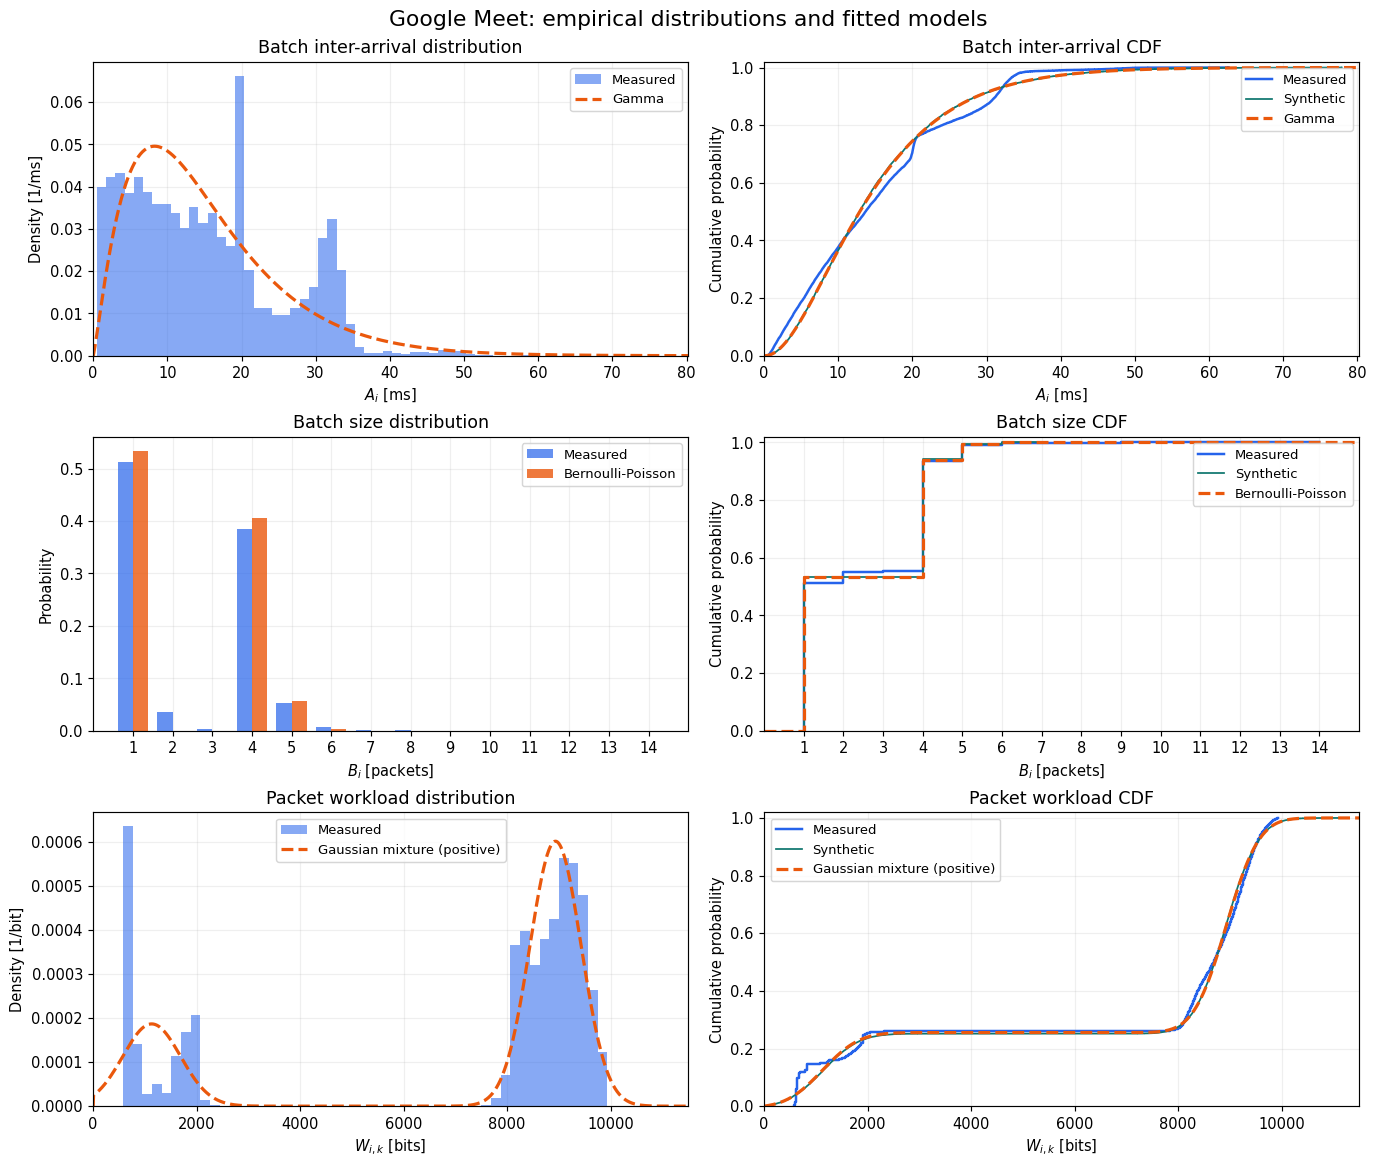

In [11]:
# Distribution plots
measured_samples = [A, B, W]
synthetic_samples = [A_final, B_final, W_final]
factors = [1000, 1, 1]
labels = [r'$A_i$ [ms]', r'$B_i$ [packets]', r'$W_{i,k}$ [bits]']
titles = ['Batch inter-arrival', 'Batch size', 'Packet workload']
model_names = ['Gamma', 'Bernoulli-Poisson', 'Gaussian mixture (positive)']
grids = [
    np.linspace(0, 1.03 * max(A.max(), A_final.max()), 1500),
    np.arange(0, int(max(B.max(), B_final.max())) + 2),
    np.linspace(0, 1.03 * max(W.max(), W_final.max()), 1500),
]
pdfs = [models['A_i']['Gamma'].pdf, None, positive_workload_pdf]
cdfs = [final_cdfs['A_i'], final_cdfs['B_i'], final_cdfs['W_i,k']]

fig, axes = plt.subplots(3, 2, figsize=(13, 11), constrained_layout=True)
fig.suptitle('Google Meet: empirical distributions and fitted models', fontsize=15)

for row in range(3):
    measured = measured_samples[row]
    synthetic = synthetic_samples[row]
    factor = factors[row]
    grid = grids[row]
    left, right = axes[row]

    if row == 1:
        measured_pmf = np.array([np.mean(B == value) for value in grid])
        width = 0.38
        left.bar(grid - width / 2, measured_pmf, width=width,
                 color='#2563EB', alpha=0.7, label='Measured')
        left.bar(grid + width / 2, batch_poisson_pmf(grid), width=width,
                 color='#EA580C', alpha=0.8, label=model_names[row])
        left.set_ylabel('Probability')
    else:
        left.hist(factor * measured, bins=50, density=True,
                  color='#2563EB', alpha=0.55, label='Measured')
        left.plot(factor * grid, pdfs[row](grid) / factor,
                  color='#EA580C', linestyle='--', linewidth=2.2,
                  label=model_names[row])
        left.set_ylabel('Density [1/ms]' if row == 0 else 'Density [1/bit]')

    right.step(*empirical_cdf(factor * measured), where='post',
               color='#2563EB', linewidth=1.7, label='Measured')
    right.step(*empirical_cdf(factor * synthetic), where='post',
               color='#0F766E', linewidth=1.2, label='Synthetic')

    if row == 1:
        right.step(grid, cdfs[row](grid), where='post',
                   color='#EA580C', linestyle='--', linewidth=2.2,
                   label=model_names[row])
    else:
        right.plot(factor * grid, cdfs[row](grid),
                   color='#EA580C', linestyle='--', linewidth=2.2,
                   label=model_names[row])

    left.set_title(f'{titles[row]} distribution')
    right.set(title=f'{titles[row]} CDF',
              ylabel='Cumulative probability', ylim=(0, 1.02))
    left.set_ylim(bottom=0)

    for ax in [left, right]:
        ax.set_xlabel(labels[row])
        ax.set_xlim(0, factor * grid[-1])
        ax.grid(alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(fontsize=9)
        if row == 1:
            ax.set_xticks(np.arange(1, int(grid[-1])))

save_figure(fig, '02_Final_Distributions_With_Models')


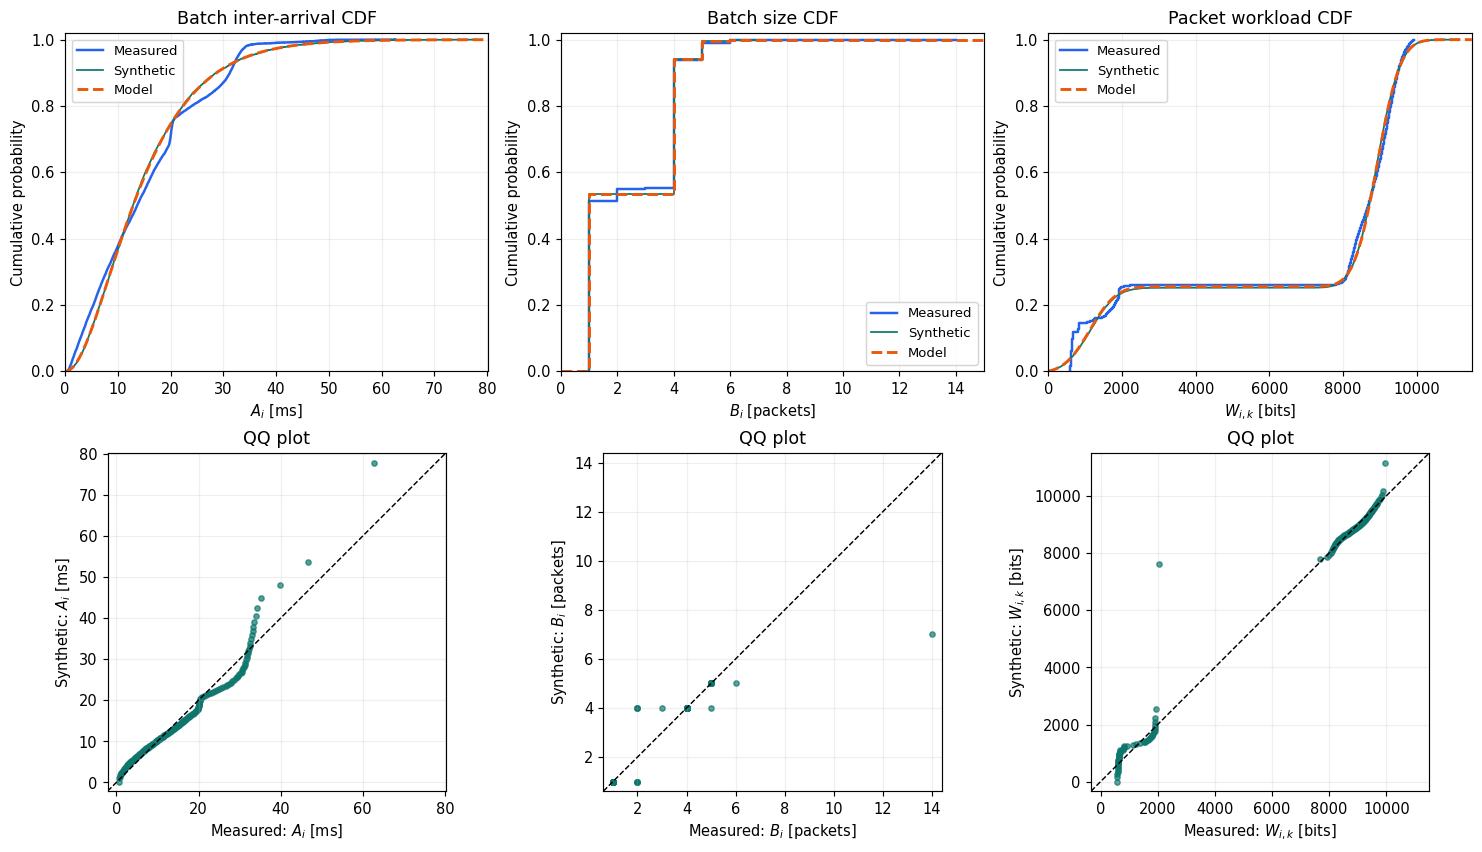

In [12]:
# CDF and QQ plots
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
labels = [r'$A_i$ [ms]', r'$B_i$ [packets]', r'$W_{i,k}$ [bits]']
titles = ['Batch inter-arrival', 'Batch size', 'Packet workload']
probabilities = np.linspace(0, 1, 201)

for column, name in enumerate(final_cdfs):
    factor = 1000 if name == 'A_i' else 1
    measured = factor * final_measured[name]
    synthetic = factor * final_synthetic[name]
    upper = max(measured.max(), synthetic.max())

    ax = axes[0, column]
    ax.step(*empirical_cdf(measured), where='post',
            color='#2563EB', linewidth=1.7, label='Measured')
    ax.step(*empirical_cdf(synthetic), where='post',
            color='#0F766E', linewidth=1.2, label='Synthetic')
    if name == 'B_i':
        grid = np.arange(0, int(upper) + 2)
        ax.step(grid, final_cdfs[name](grid), where='post',
                color='#EA580C', linestyle='--', linewidth=2, label='Model')
    else:
        grid = np.linspace(0, 1.03 * upper, 1500)
        ax.plot(grid, final_cdfs[name](grid / factor),
                color='#EA580C', linestyle='--', linewidth=2, label='Model')
    ax.set(title=f'{titles[column]} CDF', xlabel=labels[column],
           ylabel='Cumulative probability', xlim=(0, grid[-1]), ylim=(0, 1.02))
    ax.legend(fontsize=9)

    measured_q = np.quantile(measured, probabilities, method='inverted_cdf')
    synthetic_q = np.quantile(synthetic, probabilities, method='inverted_cdf')
    lower = min(measured_q.min(), synthetic_q.min())
    upper = max(measured_q.max(), synthetic_q.max())
    padding = 0.03 * (upper - lower)
    limits = (lower - padding, upper + padding)

    ax = axes[1, column]
    ax.scatter(measured_q, synthetic_q, s=13, alpha=0.7, color='#0F766E')
    ax.plot(limits, limits, 'k--', linewidth=1)
    ax.set(title='QQ plot', xlabel=f'Measured: {labels[column]}',
           ylabel=f'Synthetic: {labels[column]}', xlim=limits, ylim=limits)
    ax.set_aspect('equal', adjustable='box')

for ax in axes.flat:
    ax.grid(alpha=0.2)

save_figure(fig, '03_Final_CDF_QQ_Comparison')


## 7. Compare one-second traffic rates
Compare rate statistics, time profiles, CDFs and boxplots using complete one-second windows.

,Metric,Measured,Synthetic,Difference [%]
0,Mean 1-s rate [Mbit/s],1.125346,1.137422,1.073072
1,Std 1-s rate [Mbit/s],0.071377,0.134232,88.060891
2,Rate CV,0.063427,0.118015,86.064288
3,Rate Q05 [Mbit/s],1.064553,0.915827,-13.970702
4,Rate median [Mbit/s],1.119120,1.138352,1.718519
5,Rate Q95 [Mbit/s],1.205470,1.342587,11.374520


Complete one-second windows: 239
Rate CDF distance: 0.267782


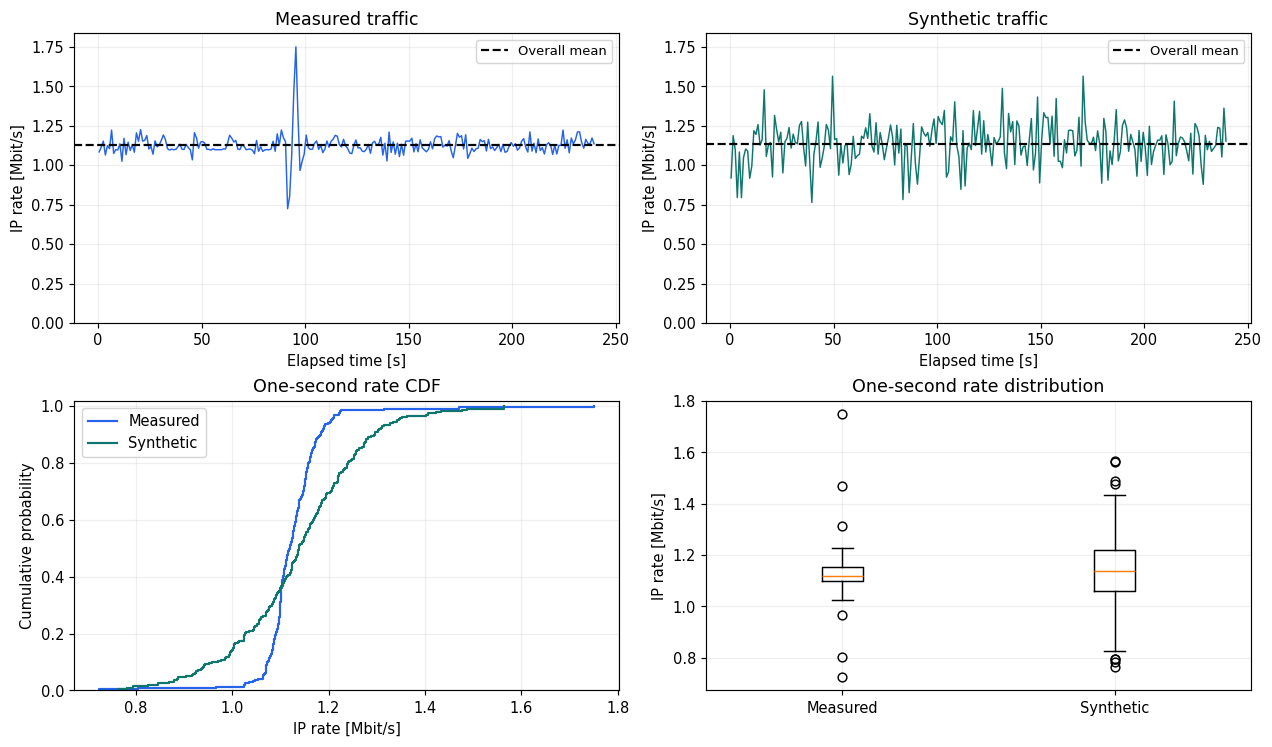

In [13]:
# Traffic rate
edges = np.r_[np.arange(0, T, 1.0), T]
durations = np.diff(edges)
measured_bits, _ = np.histogram(tau_packet, bins=edges, weights=W)
synthetic_bits, _ = np.histogram(
    packets_final['tau_packet_s'], bins=edges,
    weights=packets_final['W_i_k_bits']
)
assert np.isclose(measured_bits.sum(), W.sum(), rtol=1e-12)
assert np.isclose(synthetic_bits.sum(), W_final.sum(), rtol=1e-12)

final_rate_measured = measured_bits / durations / 1e6
final_rate_synthetic = synthetic_bits / durations / 1e6
centres = (edges[:-1] + edges[1:]) / 2

complete = np.isclose(durations, 1.0, rtol=0, atol=1e-9)
rate_measured = final_rate_measured[complete]
rate_synthetic = final_rate_synthetic[complete]

def rate_summary(x):
    return [x.mean(), x.std(ddof=1), x.std(ddof=1) / x.mean(),
            *np.quantile(x, [0.05, 0.50, 0.95])]

final_rate_comparison = pd.DataFrame({
    'Metric': ['Mean 1-s rate [Mbit/s]', 'Std 1-s rate [Mbit/s]',
               'Rate CV', 'Rate Q05 [Mbit/s]',
               'Rate median [Mbit/s]', 'Rate Q95 [Mbit/s]'],
    'Measured': rate_summary(rate_measured),
    'Synthetic': rate_summary(rate_synthetic),
})
final_rate_comparison['Difference [%]'] = 100 * (
    final_rate_comparison['Synthetic'] / final_rate_comparison['Measured'] - 1
)
display(final_rate_comparison)
print(f'Complete one-second windows: {complete.sum()}')
print(f'Rate CDF distance: {sample_cdf_distance(rate_measured, rate_synthetic):.6f}')

fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
upper = 1.05 * max(final_rate_measured.max(), final_rate_synthetic.max())

for ax, values, title, color in zip(
    axes[0], [final_rate_measured, final_rate_synthetic],
    ['Measured traffic', 'Synthetic traffic'], ['#2563EB', '#0F766E']
):
    ax.plot(centres, values, color=color, linewidth=1)
    ax.axhline(np.average(values, weights=durations), color='black',
               linestyle='--', label='Overall mean')
    ax.set(title=title, xlabel='Elapsed time [s]',
           ylabel='IP rate [Mbit/s]', ylim=(0, upper))
    ax.legend(fontsize=9)

axes[1, 0].step(*empirical_cdf(rate_measured), where='post',
                color='#2563EB', label='Measured')
axes[1, 0].step(*empirical_cdf(rate_synthetic), where='post',
                color='#0F766E', label='Synthetic')
axes[1, 0].set(title='One-second rate CDF', xlabel='IP rate [Mbit/s]',
               ylabel='Cumulative probability', ylim=(0, 1.02))
axes[1, 0].legend()

axes[1, 1].boxplot([rate_measured, rate_synthetic], showfliers=True)
axes[1, 1].set_xticks([1, 2], ['Measured', 'Synthetic'])
axes[1, 1].set(title='One-second rate distribution', ylabel='IP rate [Mbit/s]')
for ax in axes.flat:
    ax.grid(alpha=0.2)

save_figure(fig, '04_Final_Traffic_Rate_Comparison')
save_table(final_rate_comparison, 'final_traffic_rate_comparison')
save_table(pd.DataFrame({
    'Window start [s]': edges[:-1],
    'Window end [s]': edges[1:],
    'Measured rate [Mbit/s]': final_rate_measured,
    'Synthetic rate [Mbit/s]': final_rate_synthetic,
}), 'final_traffic_rate_windows')


## 8. Save the results
Save all tables, figures and metadata in `results_final` and create a downloadable results ZIP.
Fitting and comparison use the same measured trace; the results are descriptive.

In [14]:
# Save results
save_table(packet_summary, 'packet_summary')
save_table(sample_summary, 'sample_summary')
save_table(batch_pmf, 'batch_size_pmf')
save_table(parameter_table, 'model_parameters')
save_table(workload_parameters, 'workload_parameters')
save_table(fit_comparison, 'model_fit_comparison')
save_table(packets, 'measured_packets')
save_table(batches, 'measured_batches')

metadata = {
    'input_csv': csv_path.name,
    'input_sha256': input_sha256,
    'capture_window_s': [t_start, t_end],
    'analysis_duration_s': T,
    'batch_threshold_ms': delta_ms,
    'batch_rule': 'Consecutive packet gaps <= threshold belong to the same batch.',
    'workload': 'Individual IP Total Length multiplied by 8, in bits.',
    'seed': 42,
    'models': {
        'A_i': 'Gamma(lambda_A, k_A), rate and shape',
        'B_i': '1 + Z_i * (3 + X_i), independent Bern(p_B) and Poisson(lambda_B)',
        'W_i,k': 'Two-normal mixture conditioned globally on W > 0',
    },
    'assumptions': [
        'Independent batch intervals, batch sizes and individual workloads.',
        'The same measured trace is used for fitting and descriptive comparisons.',
        'Synthetic workloads are a continuous approximation in bits.',
    ],
    'software': {'numpy': np.__version__, 'pandas': pd.__version__,
                 'scipy': scipy.__version__,
                 'matplotlib': matplotlib.__version__},
}
metadata_path = output_dir / 'analysis_metadata.json'
metadata_path.write_text(json.dumps(metadata, indent=2))
saved_files.append(metadata_path)

zip_path = Path('MeetAnalysis_Final_Results.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(set(saved_files)):
        archive.write(path, arcname=path.relative_to(output_dir))
print(f'Results folder: {output_dir}')
print(f'Results archive: {zip_path}')


Results folder: results_final
Results archive: MeetAnalysis_Final_Results.zip
